# §7-бис в картинках: обратное преобразование Лапласа и вычеты

Живая версия конспекта **section7.md** — каждый шаг продублирован графиком или
численной проверкой. Для тех, кто видит вычеты (и вообще интегрирование по комплексной
плоскости) впервые.

> Принцип лучших профессоров-практиков: *формулу надо увидеть.* Если $\oint ds/s = 2\pi j$
> вызывает недоумение — постройте этот интеграл по шажкам и посмотрите, куда они
> складываются. Здесь так и поступим:

1. функция комплексного переменного — **рельеф** с воронками-полюсами;
2. интеграл по кривой — **сумма шажков** (и как контур «забывает» гладкое);
3. фокус $\oint ds/s = 2\pi j$ — **в прямом смысле на картинке**;
4. вычет — единственное, что помнит контур;
5. замыкание контура Бромвича и почему дуга «ничего не весит»;
6. три примера: $e^{-3t}$, $e^{-t}-e^{-2t}$, $\sin\omega_0 t$ — обратное преобразование
   Лапласа **по определению, численно**, против теории;
7. галерея «полюс → форма сигнала» — шпаргалка лабы в картинках.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (9, 3.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 9

print('готово: строим картинки')

готово: строим картинки


---
## 1. Функция комплексного переменного — это рельеф

Комплексное число $s = \sigma + j\omega$ — точка на плоскости. Функция $X(s)$ ставит
каждой точке число; нарисуем **высоту рельефа** $|X(s)|$. Пример с лекции:
$X(s) = \frac{1}{s+3}$ — гладкая равнина с **воронкой** в точке $s=-3$ (высота уходит
в бесконечность, поэтому верх обрезан). Такая воронка и есть **полюс** — корень
знаменателя.


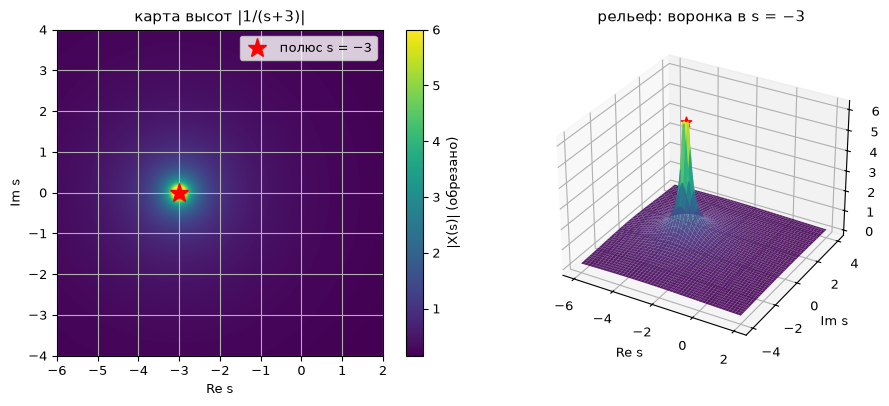

In [2]:
# Рельеф |1/(s+3)|: равнина с воронкой-полюсом в s = −3
re = np.linspace(-6, 2, 400)
im = np.linspace(-4, 4, 400)
RE, IM = np.meshgrid(re, im)
S = RE + 1j*IM
Z = np.clip(1/np.abs(S + 3), 0, 6)          # высота, обрезанная на 6

fig = plt.figure(figsize=(10, 4))
ax1 = fig.add_subplot(1, 2, 1)
pc = ax1.imshow(Z, extent=[re[0], re[-1], im[0], im[-1]], origin='lower', cmap='viridis')
ax1.plot(-3, 0, 'r*', ms=14, label='полюс s = −3')
ax1.set_xlabel('Re s'); ax1.set_ylabel('Im s'); ax1.legend(loc='upper right')
fig.colorbar(pc, ax=ax1, label='|X(s)| (обрезано)')
ax1.set_title('карта высот |1/(s+3)|')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot_surface(RE, IM, Z, cmap='viridis', linewidth=0, antialiased=True, alpha=.9)
ax2.scatter([-3], [0], [6], color='red', s=60, marker='*')
ax2.set_xlabel('Re s'); ax2.set_ylabel('Im s'); ax2.set_zlabel('|X|')
ax2.set_title('рельеф: воронка в s = −3')
plt.tight_layout(); plt.show()

---
## 2. Интеграл по кривой = сумма шажков

Режем путь $\Gamma$ на маленькие комплексные шажки $\Delta s_k$ и суммируем
$X(s_k)\,\Delta s_k$. Считаем через параметризацию: $s = s(\tau)$, $ds = s'(\tau)d\tau$.

**Разминка.** По отрезку $[0,1]$: $\int 1\,ds = 1$ (длина пути). По единичной
окружности: $\oint ds = 0$ — вышли и вернулись, шажки скомпенсировались. Увидим это
глазами: выложим шажки $\Delta s_k$ **цепочкой от нуля** (голова к хвосту) — они
замкнутся в окружность, и конец придёт ровно в $0$.


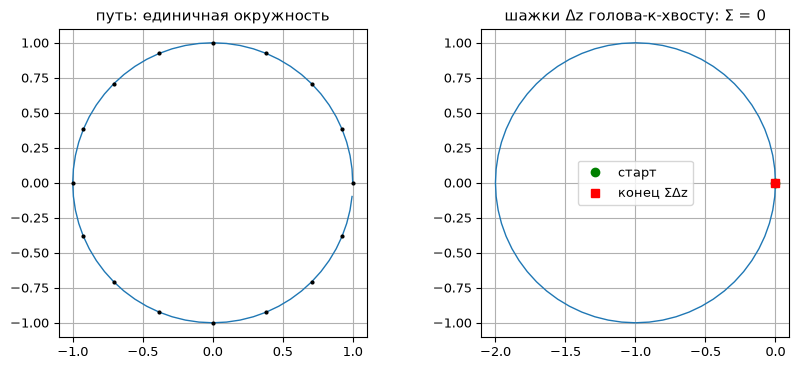

∮ ds  по N = 64 шажкам:  ΣΔz = -1.11e-16+0.00e+00j  (→ 0)
∫ ds по отрезку [0,1]:   ΣΔs = 1.0000  (→ 1)


In [3]:
# Разминка: шажки Δs по окружности, выложенные от нуля, замыкаются в 0
N = 64
th = np.linspace(0, 2*np.pi, N, endpoint=False)
z = np.exp(1j*th)                            # путь: единичная окружность
dz = np.diff(np.append(z, 1))                # шажки Δz
steps_from0 = np.concatenate([[0], np.cumsum(dz)])   # цепочка от нуля

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(z.real, z.imag, '-', lw=1)
ax[0].plot(z.real[::4], z.imag[::4], 'k.', ms=4)
ax[0].set_title('путь: единичная окружность'); ax[0].set_aspect('equal')
ax[1].plot(steps_from0.real, steps_from0.imag, lw=1)
ax[1].plot(0, 0, 'go', label='старт')
ax[1].plot(steps_from0[-1].real, steps_from0[-1].imag, 'rs', label='конец ΣΔz')
ax[1].set_title('шажки Δz голова-к-хвосту: Σ = 0'); ax[1].set_aspect('equal')
ax[1].legend()
plt.show()

print(f'∮ ds  по N = {N} шажкам:  ΣΔz = {np.sum(dz):.2e}  (→ 0)')
print(f'∫ ds по отрезку [0,1]:   ΣΔs = {np.sum(np.diff(np.linspace(0, 1, N))):.4f}  (→ 1)')

---
## 3. Фокус: обход вокруг воронки наматывает 2πj

Подставим $s = e^{j\theta}$ в $\oint ds/s$: множители $e^{j\theta}$ сокращаются,
остаётся $j\,d\theta$ — и за полный круг набегает ровно $2\pi j$.

Проверим на картинке: выложим шажки **подынтегрального выражения** $f(s)\,\Delta s$
голова-к-хвосту для $f = s^n$ при разных $n$:

* $n = 0, \pm1, \pm2, \ldots$ — шажки образуют замкнутые петельки (одинарные или
  двойные обходы) → сумма $0$;
* $n = -1$ — все шажки смотрят «вверх» ($j\,d\theta$) и выстраиваются в **прямую
  линию до высоты $2\pi j$** → сумма $2\pi j$.

Контур «забывает» всё, кроме воронки $1/s$.


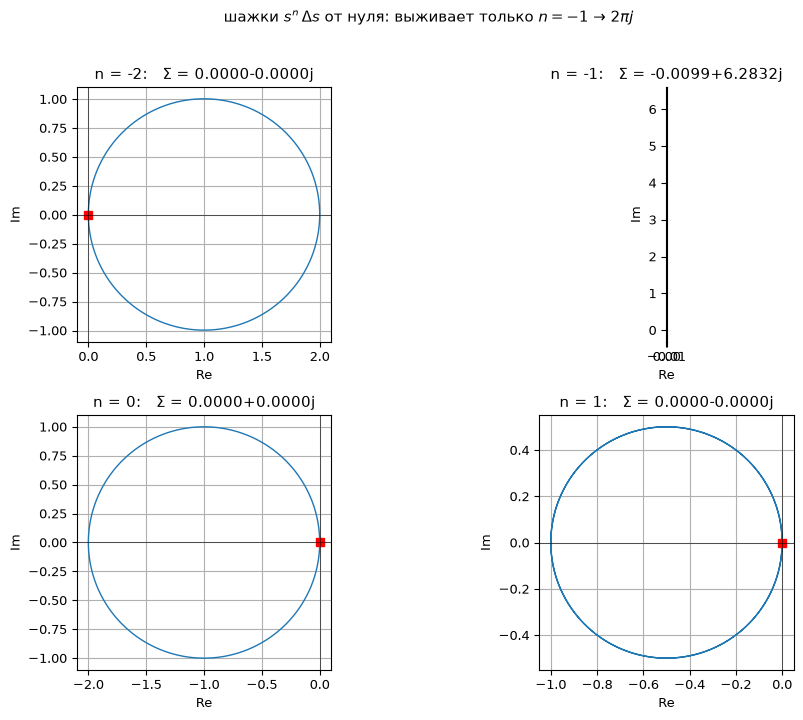

сходимость ∮ds/s с ростом числа шажков:
  N =     100:  Σ = -1.97e-01 +6.279052j   (цель: 0 + 6.283185j)
  N =    1000:  Σ = -1.97e-02 +6.283144j   (цель: 0 + 6.283185j)
  N =   10000:  Σ = -1.97e-03 +6.283185j   (цель: 0 + 6.283185j)
  N =  100000:  Σ = -1.97e-04 +6.283185j   (цель: 0 + 6.283185j)
  N = 1000000:  Σ = -1.97e-05 +6.283185j   (цель: 0 + 6.283185j)


In [4]:
# Шажки f(s)·Δs голова-к-хвосту для f = s^n: только n = −1 добирается до 2πj
N = 2000
th = np.linspace(0, 2*np.pi, N, endpoint=False)
z = np.exp(1j*th)
dz = np.diff(np.append(z, 1))

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, n in zip(axes.flat, [-2, -1, 0, 1]):
    steps = z**n * dz
    chain = np.concatenate([[0], np.cumsum(steps)])
    ax.plot(chain.real, chain.imag, lw=1)
    ax.plot(0, 0, 'go', ms=5); ax.plot(chain[-1].real, chain[-1].imag, 'rs', ms=6)
    ax.set_title(f'n = {n}:   Σ = {chain[-1]:.4f}')
    ax.set_aspect('equal'); ax.axhline(0, c='k', lw=.4); ax.axvline(0, c='k', lw=.4)
    ax.set_xlabel('Re'); ax.set_ylabel('Im')
plt.suptitle(r'шажки $s^n\,\Delta s$ от нуля: выживает только $n=-1$ → $2\pi j$', y=1.02)
plt.tight_layout(); plt.show()

print('сходимость ∮ds/s с ростом числа шажков:')
for N in (100, 10**3, 10**4, 10**5, 10**6):
    th = np.linspace(0, 2*np.pi, N, endpoint=False)
    z = np.exp(1j*th)
    dz = np.diff(np.append(z, 1))
    s = np.sum(z**(-1)*dz)
    print(f'  N = {N:7d}:  Σ = {s.real:+.2e} {s.imag:+.6f}j   (цель: 0 + 6.283185j)')

---
## 4. Вычет — «сила воронки»

Вблизи полюса $s_0$ функция раскладывается (ряд Лорана) на воронку + гладкую часть:

$$X(s) = \frac{a_{-1}}{s-s_0} + \underbrace{a_0 + a_1(s-s_0) + \ldots}_{\text{Коши: даёт }0}$$

Вычет $\operatorname*{res} = a_{-1}$ — то единственное число, которое «помнит» обход.
Для простого полюса: $\operatorname*{res} = \lim_{s\to s_0}(s-s_0)X(s)$ — и этот предел
не зависит от направления подхода (в отличие от самого $X(s)$, который уходит в ∞!).
Проверим численно для $X = e^s/(s+3)$, $s_0 = -3$: сама $X$ взрывается, а
$(s-s_0)X(s) \to e^{-3}$ с любой стороны.


In [5]:
# Вычет как предел с разных направлений подхода: всегда одно и то же число
# пример: X(s) = e^s/(s+3) — сама X у полюса взрывается, а (s−s0)X(s) имеет предел
s0, eps = -3 + 0j, 1e-6
Xloc = lambda s: np.exp(s)/(s + 3)
directions = {
    'справа (вещ.)': +1+0j, 'слева (вещ.)': -1+0j,
    'сверху (мним.)': +1j,  'снизу (мним.)': -1j,
    'по диагонали ↗': (1+1j)/np.sqrt(2), 'по диагонали ↙': (-1-1j)/np.sqrt(2),
}
print('X(s) = e^s/(s+3),  полюс s0 = −3:')
for name, d in directions.items():
    s = s0 + eps*d
    print(f'  подход {name:15s}:  |X| → {abs(Xloc(s)):>12.0f} (∞!),   (s−s0)·X(s) = {(s-s0)*Xloc(s):.6f}')
print(f'\nпредел = e^{{−3}} = {np.exp(-3):.6f} со всех сторон — это и есть вычет')

# и рецепт N/D′ для дробей: res = N(s0)/D′(s0)
print('\nрецепт N/D′ для X = 1/((s+1)(s+2)), D′ = 2s+3:')
for sk in (-1, -2):
    print(f'  полюс s = {sk}:  N/D′ = {1.0/(2*sk+3):+.4f}')


X(s) = e^s/(s+3),  полюс s0 = −3:
  подход справа (вещ.)  :  |X| →        49787 (∞!),   (s−s0)·X(s) = 0.049787+0.000000j
  подход слева (вещ.)   :  |X| →        49787 (∞!),   (s−s0)·X(s) = 0.049787+0.000000j
  подход сверху (мним.) :  |X| →        49787 (∞!),   (s−s0)·X(s) = 0.049787+0.000000j
  подход снизу (мним.)  :  |X| →        49787 (∞!),   (s−s0)·X(s) = 0.049787-0.000000j
  подход по диагонали ↗ :  |X| →        49787 (∞!),   (s−s0)·X(s) = 0.049787+0.000000j
  подход по диагонали ↙ :  |X| →        49787 (∞!),   (s−s0)·X(s) = 0.049787-0.000000j

предел = e^{−3} = 0.049787 со всех сторон — это и есть вычет

рецепт N/D′ для X = 1/((s+1)(s+2)), D′ = 2s+3:
  полюс s = -1:  N/D′ = +1.0000
  полюс s = -2:  N/D′ = -1.0000


### 4.1. Откуда берётся ряд Лорана и как его получить

**Почему Тейлора не хватает:** ряд Тейлора требует гладкости в самой точке, а у
полюса функция взрывается. Выход — разрешить **отрицательные степени**
$(s-s_0)^{-1}, (s-s_0)^{-2},\ldots$, которые как раз умеют взрываться. Ряд сходится
в «проколотом диске» $0<|s-s_0|<R$ вокруг полюса ($R$ — до ближайшей другой
особенности) и единственен в нём.

**Три способа получить:**
1. **элементарные дроби** — для рациональных $X(s)$ (все цепи лабы!) это *и есть*
   ряд Лорана: главная часть у полюса — его дробь $\frac{a_{-1}}{s-s_0}$;
2. **выделить особенность**: $X=\frac{\varphi(s)}{s-s_0}$, где $\varphi$ гладкая;
   ряд Тейлора числителя, делённый на $(s-s_0)$, даёт Лорана — и формула вычета
   $a_{-1}=\varphi(s_0)=\lim (s-s_0)X(s)$ возникает сама собой;
3. **геометрическая прогрессия** $\frac{1}{1-w}=1+w+w^2+\ldots$ — почленное деление.

Проверим способы 1–2 символически (SymPy) и посмотрим, как частичные суммы
Лорана догоняют точную функцию на окружности вокруг полюса.

Способ 1. X = 1/((s+1)(s+2)):
   -1/(s + 2) + 1/(s + 1)  — у полюса −1 вычет +1, у −2 вычет −1

Способ 2. X = e^s/(s+3), полюс s0 = −3; обозначим u = s+3:
  Тейлор числителя φ по u = s+3:
    u**6*exp(-3)/720 + u**5*exp(-3)/120 + u**4*exp(-3)/24 + u**3*exp(-3)/6 + u**2*exp(-3)/2 + u*exp(-3) + exp(-3)
  ряд Лорана X = φ/u:
    u**5*exp(-3)/720 + u**4*exp(-3)/120 + u**3*exp(-3)/24 + u**2*exp(-3)/6 + u*exp(-3)/2 + exp(-3) + exp(-3)/u
  коэффициент a₋₁ = φ(s0) = exp(−3) = 0.0497871 — вычет!


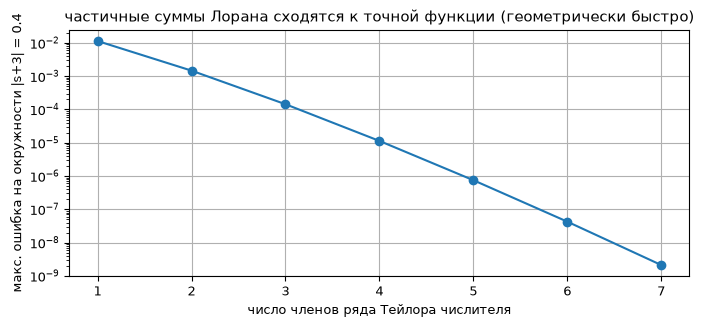

In [6]:
# Способ 1: элементарные дроби = ряд Лорана. Способ 2: Тейлор числителя / (s−s0)
import sympy as sp
s, u = sp.symbols('s u')

print('Способ 1. X = 1/((s+1)(s+2)):')
print('  ', sp.apart(1/((s + 1)*(s + 2)), s), ' — у полюса −1 вычет +1, у −2 вычет −1')

print('\nСпособ 2. X = e^s/(s+3), полюс s0 = −3; обозначим u = s+3:')
tay_u = sp.series(sp.exp(u - 3), u, 0, 7).removeO()       # Тейлор числителя по (s+3)
print('  Тейлор числителя φ по u = s+3:')
print('   ', tay_u)
print('  ряд Лорана X = φ/u:')
print('   ', sp.expand(tay_u/u))
print('  коэффициент a₋₁ = φ(s0) = exp(−3) =', sp.N(sp.exp(-3), 6), '— вычет!')

# частичные суммы Лорана против точной функции на окружности |s+3| = 0.4
X_exact = lambda sv: np.exp(sv)/(sv + 3)
sc = -3 + 0.4*np.exp(1j*np.linspace(0, 2*np.pi, 73))

errs = []
for n in range(1, 8):                                     # n членов Тейлора числителя
    series = sp.series(sp.exp(u - 3), u, 0, n + 1).removeO()/u
    f = sp.lambdify(u, series, 'numpy')
    errs.append(np.max(np.abs(f(sc + 3) - X_exact(sc))))
plt.figure(figsize=(8, 3.2))
plt.semilogy(range(1, 8), errs, 'o-')
plt.xlabel('число членов ряда Тейлора числителя')
plt.ylabel('макс. ошибка на окружности |s+3| = 0.4')
plt.title('частичные суммы Лорана сходятся к точной функции (геометрически быстро)')
plt.show()

### 4.2. Почему контур помнит только $a_{-1}$: лестница логарифма

Интеграл по замкнутому пути = $W(\text{конец})-W(\text{начало})$, где $W$ —
первообразная. У всех степеней $z^n$ при $n\ne-1$ первообразная
$\frac{z^{n+1}}{n+1}$ **однозначна**: обошли круг — конец совпал с началом,
интеграл $0$. А у $\frac1z$ первообразная $\ln z$ — **многозначная**: её мнимая
часть $\arg z$ за каждый полный оборот поднимается на $2\pi$ — **этаж винтовой
лестницы**. Конец не совпадает с началом: смещение ровно $2\pi j$. Именно поэтому
всё «забывается», кроме коэффициента при $\frac1{s-s_0}$.

Физический смысл: полюс — **точечный вихрь** («заряд»), вычет — его циркуляция;
теорема о вычетах — теорема Стокса/Гаусса для суммы вихрей: *обход считает
заряды внутри*.

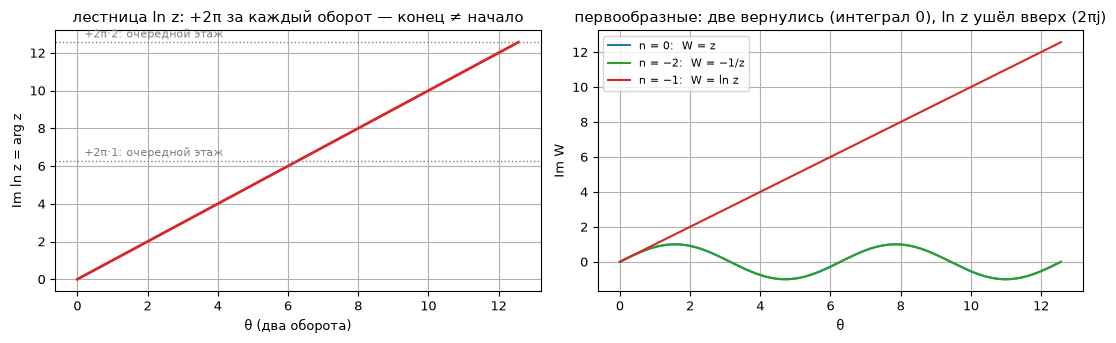

Итог обхода = W(конец) − W(начало):
  n = 0:   +0.0e+00  — вернулся, интеграл 0
  n = −2:  +0.0e+00  — вернулся, интеграл 0
  n = −1: смещение 12.5664j = 2πj × 2 оборота — только он и помнится


In [7]:
# Винтовая лестница логарифма и однозначные первообразные
th = np.linspace(0, 4*np.pi, 2000)          # два полных оборота
z = np.exp(1j*th)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(th, np.unwrap(np.angle(z)), lw=2, color='tab:red')
for k in (1, 2):
    ax[0].axhline(2*np.pi*k, color='gray', ls=':', lw=1)
    ax[0].text(0.2, 2*np.pi*k + 0.25, f'+2π·{k}: очередной этаж', fontsize=8, color='gray')
ax[0].set_xlabel('θ (два оборота)'); ax[0].set_ylabel('Im ln z = arg z')
ax[0].set_title('лестница ln z: +2π за каждый оборот — конец ≠ начало')

for n, c, name in [(0, 'tab:blue', 'n = 0:  W = z'),
                   (-2, 'tab:green', 'n = −2:  W = −1/z'),
                   (-1, 'tab:red', 'n = −1:  W = ln z')]:
    W = z**(n + 1)/(n + 1) if n != -1 else 1j*th
    ax[1].plot(th, W.imag, color=c, lw=1.5, label=name)
ax[1].set_xlabel('θ'); ax[1].set_ylabel('Im W')
ax[1].set_title('первообразные: две вернулись (интеграл 0), ln z ушёл вверх (2πj)')
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print('Итог обхода = W(конец) − W(начало):')
print('  n = 0:  ', f'{(z[-1]**1/1 - z[0]).real:+.1e}', ' — вернулся, интеграл 0')
print('  n = −2: ', f'{(-1/z[-1] - (-1/z[0])).real:+.1e}', ' — вернулся, интеграл 0')
print('  n = −1: смещение', f'{4*np.pi:.4f}j = 2πj × 2 оборота — только он и помнится')

---
## 5. Замыкаем контур: почему дуга «ничего не весит»

Обратное преобразование Лапласа — интеграл по вертикальной прямой
$\operatorname{Re} s = \sigma$ (прямая Бромвича, правее всех полюсов). Вместо
«лобового» счёта достраиваем прямой отрезок дугой **слева** до замкнутого контура.
При $t>0$ на дуге $\operatorname{Re} s < 0$, и множитель $e^{st}$ экспоненциально
затухает — вклад дуги стремится к нулю (лемма Жордана). Остаётся сумма вычетов
всех полюсов внутри:

$$x(t) = \sum_k \operatorname*{res}_{s_k}\bigl[X(s)e^{st}\bigr]$$

Посмотрим: где «живёт» подынтегральное выражение $|X(s)e^{st}|$ — и как быстро
истощается дуга с ростом радиуса.


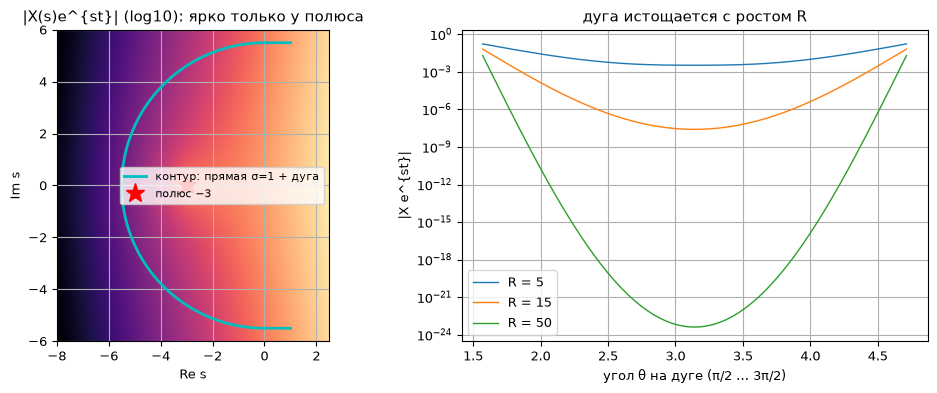

вклад дуги:            -2.29e-16 +0.0313j   (истощается при R→∞)
крышечки (2 шт.):      -1.39e-17 +0.0407j
прямая σ=1:            +0.00e+00 +0.2408j
ПОЛНЫЙ замкн. контур:  -2.50e-16 +0.3128j
2πj × res (res = e^{−3t} = 0.0498):     +0.00e+00 +0.3128j
теорема о вычетах сходится численно — при любом R, лишь бы полюс был внутри


In [8]:
# Контур Бромвича + затухание вклада дуги с ростом радиуса
t = 1.0
fig = plt.figure(figsize=(10, 4))

ax1 = fig.add_subplot(1, 2, 1)
re = np.linspace(-8, 2.5, 500); im = np.linspace(-6, 6, 500)
RE, IM = np.meshgrid(re, im)
logF = np.log10(np.abs(np.exp((RE+1j*IM)*t)/(RE+1j*IM + 3)) + 1e-12)
pc = ax1.imshow(logF, extent=[re[0], re[-1], im[0], im[-1]], origin='lower', cmap='magma')
R = 5.5
th_arc = np.linspace(np.pi/2, 3*np.pi/2, 200)
arc = R*np.exp(1j*th_arc)
ax1.plot(np.concatenate([[1], arc.real, [1]]), np.concatenate([[R], arc.imag, [-R]]),
         'c-', lw=2, label='контур: прямая σ=1 + дуга')
ax1.plot(-3, 0, 'r*', ms=14, label='полюс −3')
ax1.set_xlim(re[0], re[-1]); ax1.set_ylim(im[0], im[-1])
ax1.set_xlabel('Re s'); ax1.set_ylabel('Im s'); ax1.legend(fontsize=8)
ax1.set_title('|X(s)e^{st}| (log10): ярко только у полюса')

ax2 = fig.add_subplot(1, 2, 2)
th = np.linspace(np.pi/2, 3*np.pi/2, 4000)
for R in (5, 15, 50):
    s = R*np.exp(1j*th)
    ax2.semilogy(th, np.abs(np.exp(s*t)/(s+3)) + 1e-300, lw=1, label=f'R = {R}')
ax2.set_xlabel('угол θ на дуге (π/2 … 3π/2)'); ax2.set_ylabel('|X e^{st}|')
ax2.legend(); ax2.set_title('дуга истощается с ростом R')
plt.tight_layout(); plt.show()

# численно: интеграл по ЗАМКНУТОМУ контуру = 2πj × вычет (теорема точна при любом R!)
R, N = 20, 400000
th = np.linspace(np.pi/2, 3*np.pi/2, N)
arc_s = R*np.exp(1j*th)
I_arc = np.trapezoid(np.exp(arc_s*t)/(arc_s+3)*1j*arc_s, th)      # дуга: ds = j·s·dθ
w = np.linspace(-R, R, N)
line_s = 1 + 1j*w
I_line = np.trapezoid(np.exp(line_s*t)/(line_s+3)*1j, w)          # прямая: ds = j·dw
x = np.linspace(0, 1, 20001)                                      # «крышечки», замыкающие контур
I_top = np.trapezoid(np.exp((x + 1j*R)*t)/(x + 1j*R + 3), x[::-1])   # 1+jR → jR
I_bot = np.trapezoid(np.exp((x - 1j*R)*t)/(x - 1j*R + 3), x)          # −jR → 1−jR
I_total = I_arc + I_line + I_top + I_bot
print(f'вклад дуги:            {I_arc.real:+.2e} {I_arc.imag:+.4f}j   (истощается при R→∞)')
print(f'крышечки (2 шт.):      {(I_top + I_bot).real:+.2e} {(I_top + I_bot).imag:+.4f}j')
print(f'прямая σ=1:            {I_line.real:+.2e} {I_line.imag:+.4f}j')
print(f'ПОЛНЫЙ замкн. контур:  {I_total.real:+.2e} {I_total.imag:+.4f}j')
print(f'2πj × res (res = e^{{−3t}} = {np.exp(-3*t):.4f}):     {0:+.2e} {2*np.pi*np.exp(-3*t):+.4f}j')
print('теорема о вычетах сходится численно — при любом R, лишь бы полюс был внутри')

---
## 6. Пример 1: $X(s) = 1/(s+3)$ — по определению против теории

Шаг 1: полюс $s_1 = -3$. Шаг 2: $\operatorname*{res} = \lim (s+3)\frac{e^{st}}{s+3} = e^{-3t}$.
Шаг 3: сумма из одного слагаемого — $x(t) = e^{-3t}$.

Теперь честно посчитаем **сам интеграл по определению** — по вертикальной прямой
$\sigma = 1$, численно, и положим точки на теоретическую кривую. Бонус-наблюдение:
в точке разрыва $t = 0$ интеграл даёт **полусумму скачка** $(1+0)/2 = 0.5$ —
классический эффект Дирихле (то же семейство, что ушки Гиббса из §4 лекции).


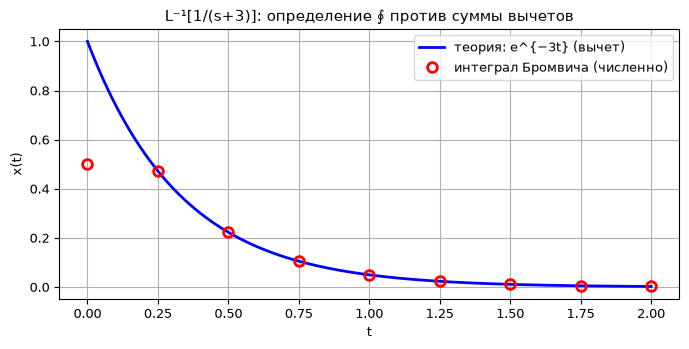

точка t=0: численно 0.4994 = полусумма скачка (1+0)/2 — эффект Дирихле!
макс. расхождение при t>0: 7.22e-04


In [9]:
# Численный интеграл Бромвича против теории: 1/(s+3)
def bromwich(X, t, sigma=1.0, Omega=2000.0, N=2**20):
    w = np.linspace(-Omega, Omega, N)
    s = sigma + 1j*w
    return np.trapezoid(X(s)*np.exp(s*t), w).real/(2*np.pi)   # ds = j·dw

X1 = lambda s: 1/(s + 3)
tt = np.linspace(0, 2, 400)
t_probe = np.linspace(0, 2, 9)
x_num = np.array([bromwich(X1, t) for t in t_probe])

plt.figure(figsize=(8, 3.5))
plt.plot(tt, np.exp(-3*tt), 'b-', lw=2, label='теория: e^{−3t} (вычет)')
plt.plot(t_probe, x_num, 'ro', ms=7, mfc='none', mew=2, label='интеграл Бромвича (численно)')
plt.xlabel('t'); plt.ylabel('x(t)'); plt.legend()
plt.title('L⁻¹[1/(s+3)]: определение ∮ против суммы вычетов')
plt.show()
print(f'точка t=0: численно {x_num[0]:.4f} = полусумма скачка (1+0)/2 — эффект Дирихле!')
print('макс. расхождение при t>0:',
      f'{np.max(np.abs(x_num[1:] - np.exp(-3*t_probe[1:]))):.2e}')

---
## 7. Пример 2: $X(s) = 1/((s+1)(s+2))$ — два полюса, два вклада

Полюсы $-1$ и $-2$; вычеты $e^{-t}$ и $-e^{-2t}$; сумма $x(t) = e^{-t} - e^{-2t}$
(проверка на $t=0$: $1-1=0$ ✓). Каждый полюс «выдыхает» свою экспоненту — увидим
оба вклада и их сумму на графике, плюс контрольные точки численного интеграла.


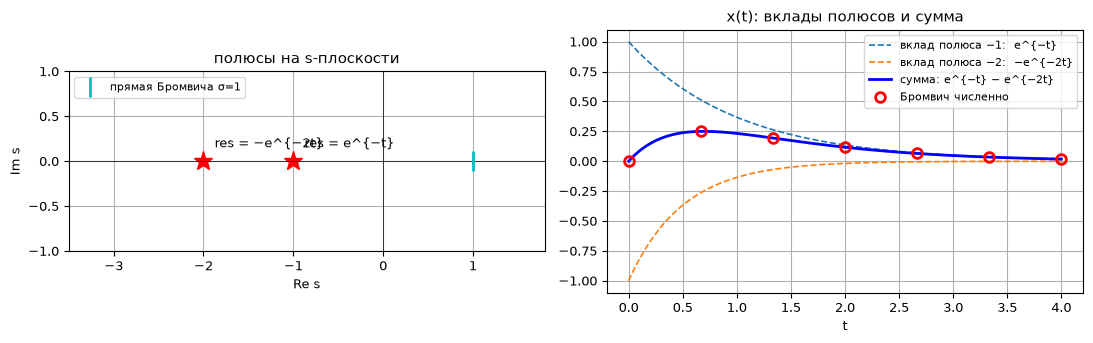

x(0) = 0.0 (проверка: 1 − 1 = 0)


In [10]:
# Два полюса — два вклада: 1/((s+1)(s+2))
X2 = lambda s: 1/((s + 1)*(s + 2))
tt = np.linspace(0, 4, 400)
c1, c2 = np.exp(-tt), -np.exp(-2*tt)
t_probe = np.linspace(0, 4, 7)
x_num = [bromwich(X2, t, Omega=400) for t in t_probe]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(-1, 0, 'r*', ms=14); ax[0].plot(-2, 0, 'r*', ms=14)
for sk, lab in [(-1, 'res = e^{−t}'), (-2, 'res = −e^{−2t}')]:
    ax[0].annotate(lab, (sk, 0), textcoords='offset points', xytext=(8, 10), fontsize=9)
ax[0].axhline(0, c='k', lw=.5); ax[0].axvline(0, c='k', lw=.5)
ax[0].plot([1], [0], 'c|', ms=15, mew=2, label='прямая Бромвича σ=1')
ax[0].set_xlim(-3.5, 1.8); ax[0].set_ylim(-1, 1); ax[0].set_aspect('equal')
ax[0].set_xlabel('Re s'); ax[0].set_ylabel('Im s'); ax[0].legend(fontsize=8)
ax[0].set_title('полюсы на s-плоскости')

ax[1].plot(tt, c1, '--', lw=1.2, label='вклад полюса −1:  e^{−t}')
ax[1].plot(tt, c2, '--', lw=1.2, label='вклад полюса −2:  −e^{−2t}')
ax[1].plot(tt, c1 + c2, 'b-', lw=2, label='сумма: e^{−t} − e^{−2t}')
ax[1].plot(t_probe, x_num, 'ro', ms=7, mfc='none', mew=2, label='Бромвич численно')
ax[1].set_xlabel('t'); ax[1].legend(fontsize=8)
ax[1].set_title('x(t): вклады полюсов и сумма')
plt.tight_layout(); plt.show()
print('x(0) =', f'{(c1 + c2)[0]:.1f}', '(проверка: 1 − 1 = 0)')

---
## 8. Пример 3: пара полюсов на мнимой оси — $\sin\omega_0 t$

$X(s) = \frac{\omega_0}{s^2+\omega_0^2}$ имеет комплексно-сопряжённые полюсы
$s_{1,2} = \pm j\omega_0$. Вычеты — комплексные числа
$\frac{e^{\pm j\omega_0 t}}{2j}$, а их сумма по формуле Эйлера — вещественная
синусоида. Сдвинем пару левее ($-\alpha \pm j\omega_0$) — получим затухающее
колебание $e^{-\alpha t}\sin\omega_0 t$: это и есть «звон» колебательного разряда
из §11 лабы. Чем ближе полюсы к мнимой оси, тем дольше звон (выше добротность).


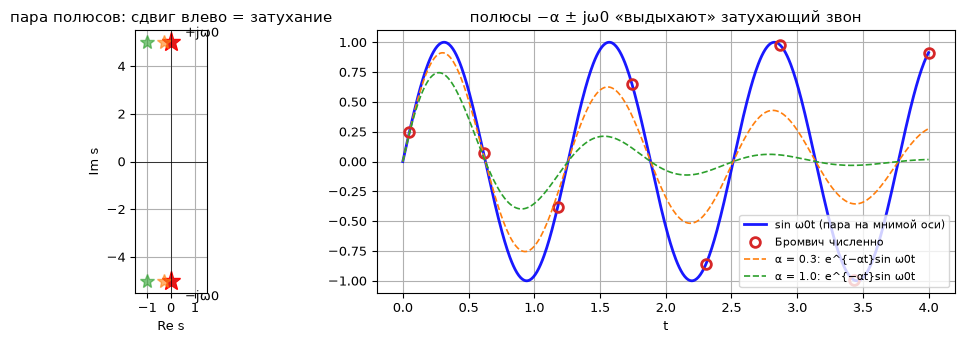

макс. расхождение числ./теории для sin: 1.14e-03


In [11]:
# Пара полюсов ±jω0 → sin ω0t;  сдвиг влево → затухающий «звон»
w0 = 5.0
X3 = lambda s: w0/(s**2 + w0**2)
tt = np.linspace(0, 4, 600)
t_probe = np.linspace(0.05, 4, 8)
x_num = [bromwich(X3, t, sigma=0.5, Omega=150) for t in t_probe]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(0, w0, 'r*', ms=14); ax[0].plot(0, -w0, 'r*', ms=14)
ax[0].annotate('+jω0', (0, w0), textcoords='offset points', xytext=(10, 4))
ax[0].annotate('−jω0', (0, -w0), textcoords='offset points', xytext=(10, -14))
for al, c in [(0.0, 'tab:red'), (0.3, 'tab:orange'), (1.0, 'tab:green')]:
    ax[0].plot([-al, -al], [w0, -w0], '*', color=c, ms=10, alpha=.6)
ax[0].axhline(0, c='k', lw=.5); ax[0].axvline(0, c='k', lw=.5)
ax[0].set_xlim(-1.5, 1.5); ax[0].set_aspect('equal')
ax[0].set_xlabel('Re s'); ax[0].set_ylabel('Im s')
ax[0].set_title('пара полюсов: сдвиг влево = затухание')

ax[1].plot(tt, np.sin(w0*tt), 'b-', lw=2, alpha=.9, label='sin ω0t (пара на мнимой оси)')
ax[1].plot(t_probe, x_num, 'o', color='tab:red', ms=7, mfc='none', mew=2, label='Бромвич численно')
for al, c in [(0.3, 'tab:orange'), (1.0, 'tab:green')]:
    ax[1].plot(tt, np.exp(-al*tt)*np.sin(w0*tt), '--', color=c, lw=1.2, label=f'α = {al}: e^{{−αt}}sin ω0t')
ax[1].set_xlabel('t'); ax[1].legend(fontsize=8)
ax[1].set_title('полюсы −α ± jω0 «выдыхают» затухающий звон')
plt.tight_layout(); plt.show()
print('макс. расхождение числ./теории для sin:', f'{np.max(np.abs(np.array(x_num) - np.sin(w0*t_probe))):.2e}')

---
## 9. Шпаргалка в картинках: полюс → форма сигнала

Сводная галерея morals раздела: **полюсы — «источники» формы сигнала.**
Вещественный полюс $-\mu$ — экспонента $e^{-\mu t}$; полюс в нуле — константа;
пара на мнимой оси — незатухающее колебание; пара $-\alpha\pm j\omega$ — звон
$e^{-\alpha t}\cos\omega t$ (добротность $Q = \omega_0/2\alpha$). Слева — карта
полюсов, справа — что они «выдыхают».


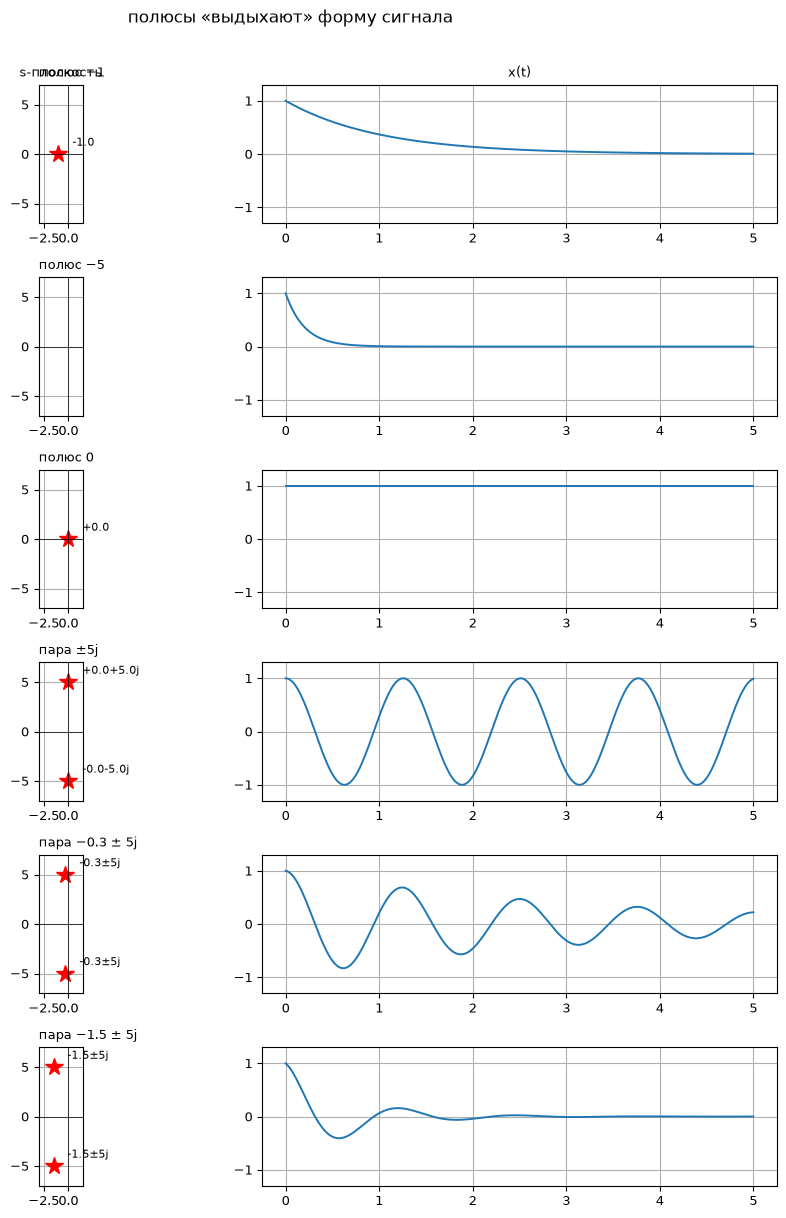

In [12]:
# Галерея «полюс → сигнал»
tt = np.linspace(0, 5, 500)
cases = [
    ('полюс −1',        [-1],                          lambda t: np.exp(-1*t)),
    ('полюс −5',        [-5],                          lambda t: np.exp(-5*t)),
    ('полюс 0',         [0],                           lambda t: np.ones_like(t)),
    ('пара ±5j',        [5j, -5j],                     lambda t: np.cos(5*t)),
    ('пара −0.3 ± 5j',  [-0.3 + 5j, -0.3 - 5j],        lambda t: np.exp(-0.3*t)*np.cos(5*t)),
    ('пара −1.5 ± 5j',  [-1.5 + 5j, -1.5 - 5j],        lambda t: np.exp(-1.5*t)*np.cos(5*t)),
]
fig, axes = plt.subplots(len(cases), 2, figsize=(10, 12))
for (name, poles, f), (axl, axr) in zip(cases, axes):
    for p in poles:
        axl.plot(p.real, p.imag, 'r*', ms=13)
        axl.annotate(f'{p:+.1f}' if not hasattr(p, 'real') or p.real == 0 else f'{p.real:+.1f}±{abs(p.imag):.0f}j'
                     if p.imag != 0 else f'{p.real:+.1f}',
                     (p.real, p.imag), textcoords='offset points', xytext=(10, 6), fontsize=8)
    axl.axhline(0, c='k', lw=.5); axl.axvline(0, c='k', lw=.5)
    axl.set_xlim(-3, 1.5); axl.set_ylim(-7, 7); axl.set_aspect('equal')
    axl.set_title(name, fontsize=9, loc='left')
    axr.plot(tt, f(tt), lw=1.4); axr.set_ylim(-1.3, 1.3)
axes[0, 0].set_title('s-плоскость', fontsize=9)
axes[0, 1].set_title('x(t)', fontsize=9)
plt.suptitle('полюсы «выдыхают» форму сигнала', y=1.01, fontsize=12)
plt.tight_layout(); plt.show()

---
## Итоги: три «почему»

1. **Почему $2\pi j$?** Один обход вокруг $1/s$ наматывает ровно $2\pi j$ — мы это
   буквально видели: шажки $j\,d\theta$ выстроились в столбик высотой $6.28j$ (§3).
2. **Почему вычет только $a_{-1}$?** Гладкие слагаемые контур «забывает» (Коши),
   помнится только воронка — и все остальные петельки-шажки замкнулись в ноль (§3).
3. **Почему дугу можно выбросить?** На левой дуге $e^{st}$ экспоненциально мала при
   $t>0$ — яркое пятно подынтегрального выражения сидит только у полюса (§5).

И главная мораль для лабораторной: **полюса передаточной функции — это расписание
затухания**. Дальше по курсу: сквозной пример с $h(t)$ и интегралом Дюамеля —
§16 лекции `Seminar_lab18.md` и ноутбук `Seminar_lab18.ipynb`.
